#  Edge-Guided LoRA-Adapted DINOv2 for Building Change Detection

**Dataset:** LEVIR-CD+  




## 1. Install required libraries

In [ ]:
#cell 1
%pip install -q "transformers>=4.45,<5" "datasets>=3.0,<5.0" peft pyarrow
%pip uninstall -y -q torchao

## 2. Environment, paths, and configuration

In [2]:
#cell 2
import os, json, math, random, time, gc
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------- storage ----------
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/Building_Change_Detection/Edge_Guided_LoRA_Project")
except ImportError:
    BASE = Path("./Edge_Guided_LoRA_Project").resolve()


V2 = {name: BASE / "v2_improved" / name for name in ["checkpoints", "logs", "results", "figures"]}
DATA_DIR = BASE / "data"
for _p in list(V2.values()) + [DATA_DIR]:
    _p.mkdir(parents=True, exist_ok=True)


LOCAL = Path("/content/cd_cache") if Path("/content").exists() else Path("./cd_cache").resolve()
LOCAL.mkdir(parents=True, exist_ok=True)


if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Your original run used the CPU (about 5 s per step), which is why training was so short.\n"
        "Fix: Runtime -> Change runtime type -> Hardware accelerator = T4 GPU (or better), then re-run from the top."
    )
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
print("GPU:", torch.cuda.get_device_name(0), f"| {GPU_GB:.1f} GB")

# ---------- configuration ----------
CFG = {
    "SEEDS": [42],
    "MODEL_ID": "facebook/dinov2-small",
    "VIT_LAYERS": (3, 6, 9, 12),
    "CROP": 392,
    "BATCH": 8,
    "TRAIN_STEPS": 4000,
    "EVAL_EVERY": 500,
    "WARMUP": 150,
    "LORA_R": 16, "LORA_ALPHA": 32, "LORA_DROPOUT": 0.05,
    "LORA_LR": 3e-4, "HEAD_LR": 1e-3, "WD": 1e-2, "GRAD_CLIP": 1.0,
    "AUX_WEIGHT": 0.4,
    "EDGE_WEIGHT": 0.5,            # edge-head loss weight (proposed model)
    "BOUNDARY_WEIGHT": 2.0,        # extra BCE weight on boundary pixels (proposed model)
    "EDGE_KERNEL": 5,
    "P_POSITIVE_CROP": 0.6,
    "NUM_WORKERS": 2,
    "TTA": True,
    "THRESHOLDS": [round(0.20 + 0.05 * i, 2) for i in range(13)],
}
assert CFG["CROP"] % 14 == 0 and CFG["CROP"] % 8 == 0 and CFG["CROP"] <= 1024

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG["SEEDS"][0])
(V2["logs"] / "v2_config.json").write_text(json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, indent=2))
print("Config saved to", V2["logs"] / "v2_config.json")

Mounted at /content/drive
GPU: Tesla T4 | 15.6 GB
Config saved to /content/drive/MyDrive/Building_Change_Detection/Edge_Guided_LoRA_Project/v2_improved/logs/v2_config.json


## 3. Download and cache LEVIR-CD+

In [3]:
#cell 3
from datasets import load_dataset

DATASET_ID = "blanchon/LEVIR_CDPlus"
HF_CACHE = DATA_DIR / "huggingface_cache"
HF_CACHE.mkdir(parents=True, exist_ok=True)

CACHE = {s: {k: LOCAL / f"{s}_{k}.npy" for k in ("t1", "t2", "mask")} for s in ("train", "test")}
DONE = {s: LOCAL / f"{s}_cache_done.json" for s in ("train", "test")}

def cache_ready(split):
    return DONE[split].exists() and all(p.exists() for p in CACHE[split].values())

def open_arrays(paths):
    return {k: np.load(p, mmap_mode="r") for k, p in paths.items()}

if all(cache_ready(s) for s in ("train", "test")):
    print("Local array cache already built; skipping conversion.")
else:
    hf = load_dataset(DATASET_ID, cache_dir=str(HF_CACHE))
    assert "train" in hf and "test" in hf
    for split in ("train", "test"):
        if cache_ready(split):
            continue
        ds = hf[split]
        n = len(ds)
        print(f"Converting {split}: {n} image pairs ...")
        a1 = np.lib.format.open_memmap(CACHE[split]["t1"], mode="w+", dtype=np.uint8, shape=(n, 1024, 1024, 3))
        a2 = np.lib.format.open_memmap(CACHE[split]["t2"], mode="w+", dtype=np.uint8, shape=(n, 1024, 1024, 3))
        am = np.lib.format.open_memmap(CACHE[split]["mask"], mode="w+", dtype=np.uint8, shape=(n, 1024, 1024))
        for i in range(n):
            row = ds[i]
            im1 = np.asarray(row["image1"].convert("RGB"))
            im2 = np.asarray(row["image2"].convert("RGB"))
            mk = np.asarray(row["mask"])
            if mk.ndim == 3:
                mk = mk[..., 0]
            assert im1.shape == (1024, 1024, 3) and im2.shape == (1024, 1024, 3) and mk.shape == (1024, 1024), \
                f"Unexpected shapes at {split}[{i}]: {im1.shape}, {im2.shape}, {mk.shape}"
            a1[i] = im1
            a2[i] = im2
            am[i] = (mk > 0).astype(np.uint8)
            if (i + 1) % 100 == 0 or i + 1 == n:
                print(f"  {split}: {i + 1}/{n}")
        a1.flush(); a2.flush(); am.flush()
        del a1, a2, am
        DONE[split].write_text(json.dumps({"n": n}))
    del hf
    gc.collect()

EVAL_ARR = {s: open_arrays(CACHE[s]) for s in ("train", "test")}
for s in ("train", "test"):
    print(s, {k: v.shape for k, v in EVAL_ARR[s].items()})
assert EVAL_ARR["train"]["t1"].shape[1:] == (1024, 1024, 3)
print("Cache ready. Mask positive fraction (first 20 train images):",
      float(np.mean([EVAL_ARR["train"]["mask"][i].mean() for i in range(20)])))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005.parquet:   0%|          | 0.00/533M [00:00<?, ?B/s]

data/train-00001-of-00005.parquet:   0%|          | 0.00/453M [00:00<?, ?B/s]

data/train-00002-of-00005.parquet:   0%|          | 0.00/497M [00:00<?, ?B/s]

...

data/test-00001-of-00003.parquet:   0%|          | 0.00/439M [00:00<?, ?B/s]

data/test-00002-of-00003.parquet:   0%|          | 0.00/438M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/637 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/348 [00:00<?, ? examples/s]

Converting train: 637 image pairs ...
  train: 100/637
  train: 200/637
  train: 300/637
  train: 400/637
  train: 500/637
  train: 600/637
  train: 637/637
Converting test: 348 image pairs ...
  test: 100/348
  test: 200/348
  test: 300/348
  test: 348/348
train {'t1': (637, 1024, 1024, 3), 't2': (637, 1024, 1024, 3), 'mask': (637, 1024, 1024)}
test {'t1': (348, 1024, 1024, 3), 't2': (348, 1024, 1024, 3), 'mask': (348, 1024, 1024)}
Cache ready. Mask positive fraction (first 20 train images): 0.051503753662109374


## 4. Create or load reproducible data splits

In [4]:
#cell 4
MANIFEST_PATH = DATA_DIR / "split_manifest.json"
n_train_total = EVAL_ARR["train"]["t1"].shape[0]
n_test_total = EVAL_ARR["test"]["t1"].shape[0]

if MANIFEST_PATH.exists():
    manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    print("Reusing existing split manifest:", MANIFEST_PATH)
else:
    rng = random.Random(42)
    ids = list(range(n_train_total))
    rng.shuffle(ids)
    n_val = round(0.15 * len(ids))
    val_ids = sorted(ids[:n_val])
    train_ids = sorted(ids[n_val:])
    order = train_ids.copy()
    rng.shuffle(order)
    subsets = {f"{int(f * 100)}%": sorted(order[:round(f * len(train_ids))]) for f in [1.0, 0.5, 0.2, 0.1]}
    manifest = {
        "dataset_id": DATASET_ID, "seed": 42, "split_unit": "whole original image pair",
        "train_ids": train_ids, "validation_ids": val_ids,
        "official_test_ids": list(range(n_test_total)), "label_subsets": subsets,
    }
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print("Created new split manifest:", MANIFEST_PATH)

assert set(manifest["train_ids"]).isdisjoint(manifest["validation_ids"])
assert max(manifest["train_ids"] + manifest["validation_ids"]) < n_train_total
assert max(manifest["official_test_ids"]) < n_test_total
for key in ("100%", "50%", "20%", "10%"):
    assert key in manifest["label_subsets"], f"missing label subset {key}"
print(f"train={len(manifest['train_ids'])}  val={len(manifest['validation_ids'])}  test={len(manifest['official_test_ids'])}")
print({k: len(v) for k, v in manifest["label_subsets"].items()})

Created new split manifest: /content/drive/MyDrive/Building_Change_Detection/Edge_Guided_LoRA_Project/data/split_manifest.json
train=541  val=96  test=348
{'100%': 541, '50%': 270, '20%': 108, '10%': 54}


## 5. Training crops, augmentation, and data loaders

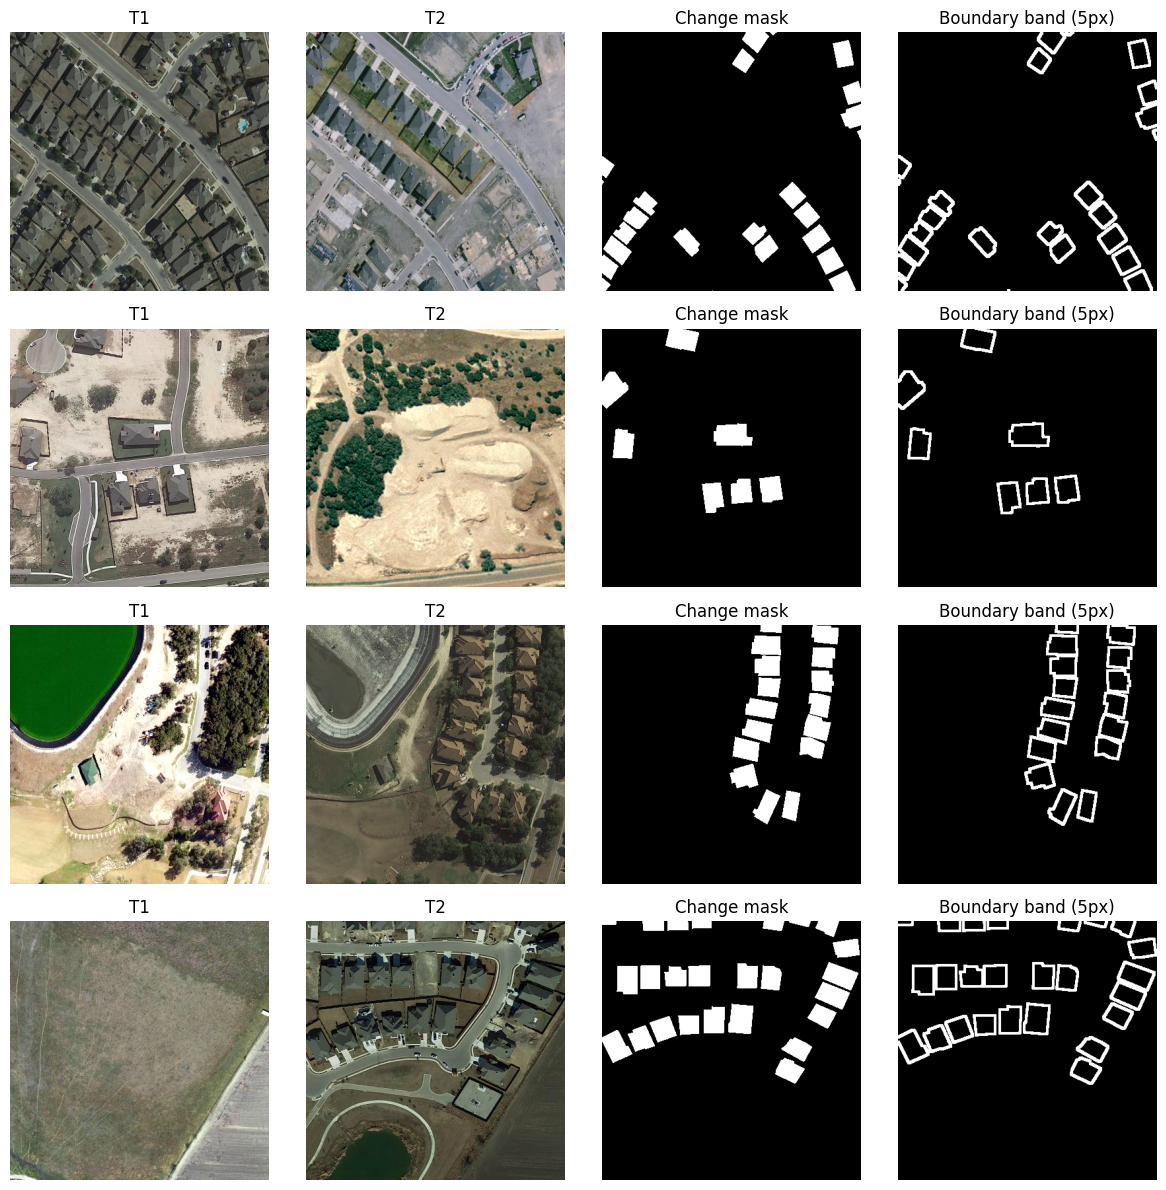

crop tensor: (3, 392, 392) (1, 392, 392) | mean changed fraction in 4 crops: 0.10242639668285847


In [5]:
#cell 5
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
IMG = 1024

def photometric_jitter(x):

    b = 1.0 + (torch.rand(1) * 2 - 1) * 0.15
    c = 1.0 + (torch.rand(1) * 2 - 1) * 0.15
    s = 1.0 + (torch.rand(1) * 2 - 1) * 0.15
    g = 1.0 + (torch.rand(3, 1, 1) * 2 - 1) * 0.04
    x = x * b * g
    m = x.mean()
    x = (x - m) * c + m
    gray = x.mean(dim=0, keepdim=True)
    x = (x - gray) * s + gray
    return x.clamp(0.0, 1.0)


class CDTrainDataset(torch.utils.data.Dataset):

    def __init__(self, paths, image_ids, crop, length, p_pos):
        self.paths = paths
        self.ids = list(image_ids)
        self.crop = crop
        self.length = int(length)
        self.p_pos = p_pos
        self._arrays = None

    def _open(self):
        if self._arrays is None:
            self._arrays = open_arrays(self.paths)
        return self._arrays

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        arrs = self._open()
        c = self.crop
        row = self.ids[int(torch.randint(len(self.ids), (1,)))]
        top = int(torch.randint(IMG - c + 1, (1,)))
        left = int(torch.randint(IMG - c + 1, (1,)))

        if float(torch.rand(1)) < self.p_pos:
            ys, xs = np.nonzero(arrs["mask"][row])
            if len(ys) > 0:
                j = int(torch.randint(len(ys), (1,)))
                cy, cx = int(ys[j]), int(xs[j])
                top = min(max(cy - int(torch.randint(c, (1,))), 0), IMG - c)
                left = min(max(cx - int(torch.randint(c, (1,))), 0), IMG - c)

        t1 = np.array(arrs["t1"][row, top:top + c, left:left + c])
        t2 = np.array(arrs["t2"][row, top:top + c, left:left + c])
        mk = np.array(arrs["mask"][row, top:top + c, left:left + c])

        t1 = torch.from_numpy(t1).permute(2, 0, 1).float().div_(255.0)
        t2 = torch.from_numpy(t2).permute(2, 0, 1).float().div_(255.0)
        mk = torch.from_numpy(mk).unsqueeze(0).float()

        if float(torch.rand(1)) < 0.5:
            t1, t2, mk = t1.flip(-1), t2.flip(-1), mk.flip(-1)
        if float(torch.rand(1)) < 0.5:
            t1, t2, mk = t1.flip(-2), t2.flip(-2), mk.flip(-2)
        k = int(torch.randint(4, (1,)))
        if k:
            t1 = torch.rot90(t1, k, dims=(-2, -1))
            t2 = torch.rot90(t2, k, dims=(-2, -1))
            mk = torch.rot90(mk, k, dims=(-2, -1))
        if float(torch.rand(1)) < 0.5:            # change is symmetric in time
            t1, t2 = t2, t1

        t1 = (photometric_jitter(t1) - IMAGENET_MEAN) / IMAGENET_STD
        t2 = (photometric_jitter(t2) - IMAGENET_MEAN) / IMAGENET_STD
        return t1.contiguous(), t2.contiguous(), mk.contiguous()


def make_loader(ds, batch_size):
    nw = CFG["NUM_WORKERS"]
    kwargs = dict(batch_size=batch_size, shuffle=False, drop_last=True, num_workers=nw, pin_memory=True)
    if nw > 0:
        kwargs["prefetch_factor"] = 4
    return torch.utils.data.DataLoader(ds, **kwargs)


def make_edge(mask, k):

    pad = k // 2
    dil = F.max_pool2d(mask, k, 1, pad)
    ero = -F.max_pool2d(-mask, k, 1, pad)
    return (dil - ero).clamp(0.0, 1.0)



import matplotlib.pyplot as plt
seed_everything(0)
_ds = CDTrainDataset(CACHE["train"], manifest["train_ids"], CFG["CROP"], length=8, p_pos=CFG["P_POSITIVE_CROP"])
_batch = [_ds[i] for i in range(4)]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i, (a, b, m) in enumerate(_batch):
    e = make_edge(m.unsqueeze(0), CFG["EDGE_KERNEL"])[0, 0]
    axes[i, 0].imshow((a * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[i, 1].imshow((b * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[i, 2].imshow(m[0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 3].imshow(e.numpy(), cmap="gray", vmin=0, vmax=1)
    for j, t in enumerate(["T1", "T2", "Change mask", f"Boundary band ({CFG['EDGE_KERNEL']}px)"]):
        axes[i, j].set_title(t); axes[i, j].axis("off")
plt.tight_layout(); plt.show()
print("crop tensor:", tuple(_batch[0][0].shape), tuple(_batch[0][2].shape),
      "| mean changed fraction in 4 crops:", float(np.mean([b[2].mean().item() for b in _batch])))
del _ds, _batch

## 6. Model architecture and LoRA setup

In [6]:
#cell 6
class ConvBNReLU(nn.Sequential):
    def __init__(self, cin, cout, k=3, s=1):
        super().__init__(
            nn.Conv2d(cin, cout, k, s, k // 2, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
        )


def temporal_cat(feat, batch):
    # feat: (2B,C,H,W) = [date1 ; date2]  ->  (B,3C,H,W) = [f1, f2, |f1-f2|]
    f1, f2 = feat[:batch], feat[batch:]
    return torch.cat([f1, f2, (f1 - f2).abs()], dim=1)


class ChangeNet(nn.Module):
    def __init__(self, vit, hidden, patch, use_edge, layers=(3, 6, 9, 12)):
        super().__init__()
        self.vit = vit
        self.hidden = hidden
        self.patch = patch
        self.layers = tuple(layers)
        self.use_edge = use_edge


        self.vit_fuse = nn.ModuleList([
            nn.Sequential(ConvBNReLU(3 * hidden, 128, k=1), ConvBNReLU(128, 128, k=3))
            for _ in self.layers
        ])
        self.vit_merge = ConvBNReLU(128 * len(self.layers), 192, k=3)


        self.enc1 = nn.Sequential(ConvBNReLU(3, 32, 3, 2), ConvBNReLU(32, 32, 3, 1))
        self.enc2 = nn.Sequential(ConvBNReLU(32, 64, 3, 2), ConvBNReLU(64, 64, 3, 1))
        self.enc3 = nn.Sequential(ConvBNReLU(64, 96, 3, 2), ConvBNReLU(96, 96, 3, 1))
        self.diff1 = ConvBNReLU(3 * 32, 32, k=1)
        self.diff2 = ConvBNReLU(3 * 64, 64, k=1)
        self.diff3 = ConvBNReLU(3 * 96, 96, k=1)

        # Decoder
        self.dec3 = nn.Sequential(ConvBNReLU(192 + 96, 128, 3), ConvBNReLU(128, 128, 3))   # stride 8
        self.dec2 = nn.Sequential(ConvBNReLU(128 + 64, 64, 3), ConvBNReLU(64, 64, 3))      # stride 4
        self.dec1 = nn.Sequential(ConvBNReLU(64 + 32, 48, 3), ConvBNReLU(48, 48, 3))       # stride 2
        self.aux_head = nn.Conv2d(64, 1, 1)                                                # deep supervision @ stride 4

        if use_edge:
            self.edge_feat = ConvBNReLU(48, 24, 3)
            self.edge_out = nn.Conv2d(24, 1, 1)
            self.guided = ConvBNReLU(48 + 24, 48, 3)
        else:
            self.refine = ConvBNReLU(48, 48, 3)      # capacity-matched stand-in for the baseline

        self.final = nn.Sequential(ConvBNReLU(48, 32, 3), nn.Conv2d(32, 1, 1))

    def vit_features(self, x):
        out = self.vit(pixel_values=x, output_hidden_states=True)
        n = x.shape[0]
        h = x.shape[-2] // self.patch
        w = x.shape[-1] // self.patch
        feats = []
        for l in self.layers:
            t = out.hidden_states[l][:, -h * w:, :]               # drop CLS (and register tokens if any)
            feats.append(t.transpose(1, 2).reshape(n, self.hidden, h, w))
        return feats

    def forward(self, x1, x2):
        B = x1.shape[0]
        size = x1.shape[-2:]
        both = torch.cat([x1, x2], dim=0)

        # ViT branch
        feats = self.vit_features(both)
        z = self.vit_merge(torch.cat(
            [m(temporal_cat(f, B)) for f, m in zip(feats, self.vit_fuse)], dim=1))      # (B,192,h,w)

        # CNN branch
        e1 = self.enc1(both)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        d1 = self.diff1(temporal_cat(e1, B))
        d2 = self.diff2(temporal_cat(e2, B))
        d3 = self.diff3(temporal_cat(e3, B))

        # Decoder
        y = F.interpolate(z, size=d3.shape[-2:], mode="bilinear", align_corners=False)
        y = self.dec3(torch.cat([y, d3], dim=1))
        y = F.interpolate(y, size=d2.shape[-2:], mode="bilinear", align_corners=False)
        y = self.dec2(torch.cat([y, d2], dim=1))
        aux = self.aux_head(y)
        y = F.interpolate(y, size=d1.shape[-2:], mode="bilinear", align_corners=False)
        y = self.dec1(torch.cat([y, d1], dim=1))

        out = {}
        if self.use_edge:
            ef = self.edge_feat(y)
            edge_logits = self.edge_out(ef)
            gate = torch.sigmoid(edge_logits)
            y = self.guided(torch.cat([y * (1.0 + gate), ef], dim=1))
            out["edge_logits"] = F.interpolate(edge_logits, size=size, mode="bilinear", align_corners=False)
        else:
            y = self.refine(y)

        y = F.interpolate(y, size=size, mode="bilinear", align_corners=False)
        out["change_logits"] = self.final(y)
        out["aux_logits"] = F.interpolate(aux, size=size, mode="bilinear", align_corners=False)
        return out


def build_model(use_edge):
    from transformers import AutoModel
    from peft import LoraConfig, get_peft_model
    base = AutoModel.from_pretrained(CFG["MODEL_ID"])
    hidden, patch = base.config.hidden_size, base.config.patch_size
    for p in base.parameters():
        p.requires_grad = False
    lora_cfg = LoraConfig(
        r=CFG["LORA_R"], lora_alpha=CFG["LORA_ALPHA"], lora_dropout=CFG["LORA_DROPOUT"],
        target_modules=["query", "key", "value"], bias="none",
    )
    vit = get_peft_model(base, lora_cfg)
    model = ChangeNet(vit, hidden, patch, use_edge=use_edge, layers=CFG["VIT_LAYERS"])
    for n, p in model.named_parameters():
        p.requires_grad = ("lora_" in n) or (not n.startswith("vit."))
    return model.to(device)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    lora = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and "lora_" in n)
    return total, trainable, lora


def trainable_state(model):

    return {k: v.detach().cpu() for k, v in model.state_dict().items()
            if ("lora_" in k) or (not k.startswith("vit."))}


def load_trainable(model, state):
    res = model.load_state_dict(state, strict=False)
    bad = list(res.unexpected_keys) + [k for k in res.missing_keys if ("lora_" in k) or (not k.startswith("vit."))]
    assert not bad, f"checkpoint mismatch, e.g.: {bad[:5]}"


print("ChangeNet defined.")

ChangeNet defined.


## 7. Loss functions, inference, and evaluation metrics

In [7]:
#cell 7
def soft_dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum()
    return 1.0 - (2.0 * inter + eps) / (p.sum() + target.sum() + eps)


def compute_loss(out, mask, variant):
    mask = mask.float()
    edge_t = make_edge(mask, CFG["EDGE_KERNEL"])
    logits = out["change_logits"].float()

    weight = 1.0 + variant["boundary_weight"] * edge_t
    bce = (F.binary_cross_entropy_with_logits(logits, mask, reduction="none") * weight).mean()
    dice = soft_dice_loss(logits, mask)
    total = bce + dice
    parts = {"bce": bce.detach(), "dice": dice.detach()}

    aux_logits = out["aux_logits"].float()
    aux = F.binary_cross_entropy_with_logits(aux_logits, mask) + soft_dice_loss(aux_logits, mask)
    total = total + CFG["AUX_WEIGHT"] * aux
    parts["aux"] = aux.detach()

    if variant["use_edge"] and "edge_logits" in out:
        el = out["edge_logits"].float()
        eloss = F.binary_cross_entropy_with_logits(el, edge_t) + soft_dice_loss(el, edge_t)
        total = total + variant["edge_weight"] * eloss
        parts["edge"] = eloss.detach()
    return total, parts


# ---------------- tiled inference ----------------
def tile_positions(size, crop):
    n = max(2, math.ceil((size - crop) / (0.85 * crop)) + 1)
    return sorted(set(int(round(v)) for v in np.linspace(0, size - crop, n)))

TILE_POS = tile_positions(IMG, CFG["CROP"])
TILE_COORDS = [(y, x) for y in TILE_POS for x in TILE_POS]
_h = torch.hann_window(CFG["CROP"], periodic=False)
TILE_WIN = (0.1 + 0.9 * torch.outer(_h, _h)).to(device)             # (crop, crop)
MEAN_D = IMAGENET_MEAN.to(device)
STD_D = IMAGENET_STD.to(device)
print("Tile origins per axis:", TILE_POS, "->", len(TILE_COORDS), "tiles per 1024x1024 image")


def to_input(arr_u8):
    x = torch.from_numpy(np.array(arr_u8)).to(device).permute(2, 0, 1).float().div_(255.0)
    return (x - MEAN_D) / STD_D


def _predict_chunk(model, a, b, tta):
    flips = [[], [2], [3], [2, 3]] if tta else [[]]
    acc = None
    for dims in flips:
        aa = torch.flip(a, dims) if dims else a
        bb = torch.flip(b, dims) if dims else b
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(aa, bb)["change_logits"]
        p = torch.sigmoid(logits.float())
        if dims:
            p = torch.flip(p, dims)
        acc = p if acc is None else acc + p
    return acc / len(flips)


@torch.no_grad()
def predict_full(model, t1_np, t2_np, tta=False):
    # Returns the (1024,1024) change-probability map for one full image pair.
    model.eval()
    c = CFG["CROP"]
    x1, x2 = to_input(t1_np), to_input(t2_np)
    a = torch.stack([x1[:, y:y + c, x:x + c] for y, x in TILE_COORDS])
    b = torch.stack([x2[:, y:y + c, x:x + c] for y, x in TILE_COORDS])
    probs = torch.cat([_predict_chunk(model, a[i:i + 9], b[i:i + 9], tta) for i in range(0, a.shape[0], 9)])
    prob = torch.zeros(IMG, IMG, device=device)
    wsum = torch.zeros(IMG, IMG, device=device)
    for i, (y, x) in enumerate(TILE_COORDS):
        prob[y:y + c, x:x + c] += probs[i, 0] * TILE_WIN
        wsum[y:y + c, x:x + c] += TILE_WIN
    return prob / wsum


def metrics_from_counts(tp, fp, fn, tn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    total = tp + fp + fn + tn
    oa = (tp + tn) / total if total else 0.0
    return {"precision": precision, "recall": recall, "f1": f1, "iou": iou, "oa": oa}


@torch.no_grad()
def evaluate(model, arrays, image_ids, thresholds, tta=False, limit=None):
    # Global pixel counts for every threshold, from full-image tiled inference.
    model.eval()
    ids = list(image_ids)[:limit] if limit else list(image_ids)
    K = len(thresholds)
    th = torch.tensor(thresholds, device=device).view(K, 1, 1)
    tp = torch.zeros(K, dtype=torch.int64, device=device)
    fp = torch.zeros(K, dtype=torch.int64, device=device)
    fn = torch.zeros(K, dtype=torch.int64, device=device)
    tn = torch.zeros(K, dtype=torch.int64, device=device)
    for row in ids:
        prob = predict_full(model, arrays["t1"][row], arrays["t2"][row], tta=tta)
        gt = torch.from_numpy(np.array(arrays["mask"][row])).to(device).bool().unsqueeze(0)
        pred = prob.unsqueeze(0) >= th
        tp += (pred & gt).sum(dim=(1, 2))
        fp += (pred & ~gt).sum(dim=(1, 2))
        fn += (~pred & gt).sum(dim=(1, 2))
        tn += (~pred & ~gt).sum(dim=(1, 2))
    tp, fp, fn, tn = tp.tolist(), fp.tolist(), fn.tolist(), tn.tolist()
    rows = []
    for k, t in enumerate(thresholds):
        m = metrics_from_counts(tp[k], fp[k], fn[k], tn[k])
        m["threshold"] = t
        rows.append(m)
    best = max(rows, key=lambda r: r["f1"])
    return {"per_threshold": rows, "best": best, "n_images": len(ids)}


def pick(ev, thr):
    return min(ev["per_threshold"], key=lambda r: abs(r["threshold"] - thr))

print("Loss + inference + evaluation utilities defined.")

Tile origins per axis: [0, 316, 632] -> 9 tiles per 1024x1024 image
Loss + inference + evaluation utilities defined.


## 8. Optimizer, training loop, and experiment runner

In [8]:
# cell 8
VARIANTS = {

    "baseline": dict(use_edge=False, boundary_weight=0.0, edge_weight=0.0),
    "proposed": dict(use_edge=True, boundary_weight=CFG["BOUNDARY_WEIGHT"], edge_weight=CFG["EDGE_WEIGHT"]),
}

def exp_name(variant_name, label_key, seed):
    return f"{variant_name}_{label_key.replace('%', '')}_s{seed}"

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda")
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler()

def build_optimizer(model):
    lora, head = [], []
    for n, p in model.named_parameters():
        if p.requires_grad:
            (lora if "lora_" in n else head).append(p)
    opt = torch.optim.AdamW(
        [{"params": lora, "lr": CFG["LORA_LR"]}, {"params": head, "lr": CFG["HEAD_LR"]}],
        weight_decay=CFG["WD"],
    )
    return opt, lora + head

def make_scheduler(opt, total_steps):
    warm = CFG["WARMUP"]
    def factor(step):
        if step < warm:
            return (step + 1) / warm
        prog = (step - warm) / max(1, total_steps - warm)
        return 0.01 + 0.99 * 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))
    return torch.optim.lr_scheduler.LambdaLR(opt, factor)

def train_step(model, opt, scaler, params, variant, t1, t2, mask):
    with torch.autocast("cuda", dtype=torch.float16):
        out = model(t1, t2)
    loss, parts = compute_loss(out, mask, variant)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(params, CFG["GRAD_CLIP"])
    scaler.step(opt)
    scaler.update()
    return loss.detach(), parts


def run_experiment(variant_name, variant, label_key="100%", seed=42, steps=None, force=False):
    steps = steps or CFG["TRAIN_STEPS"]
    name = exp_name(variant_name, label_key, seed)
    result_path = V2["results"] / f"{name}_test.json"
    if result_path.exists() and not force:
        print(f"[{name}] finished result found -> skipping ({result_path.name})")
        return json.loads(result_path.read_text())

    ckpt_dir = V2["checkpoints"] / name
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    best_path, last_path = ckpt_dir / "best.pt", ckpt_dir / "last.pt"

    seed_everything(seed)
    model = build_model(variant["use_edge"])
    total_p, train_p, lora_p = count_params(model)
    print(f"\n=== {name} | params total={total_p:,} trainable={train_p:,} (LoRA {lora_p:,}) ===")

    opt, params = build_optimizer(model)
    sched = make_scheduler(opt, steps)
    scaler = make_scaler()
    ids = manifest["label_subsets"][label_key]
    val_ids = manifest["validation_ids"]

    history, best, start = [], {"f1": -1.0, "threshold": 0.5, "step": 0}, 0
    if last_path.exists() and not force:
        ck = torch.load(last_path, map_location=device, weights_only=False)
        load_trainable(model, ck["model"])
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start, history, best = ck["step"], ck["history"], ck["best"]
        print(f"Resumed from step {start}/{steps} (best val F1 so far {best['f1']:.4f})")

    t_start = time.time()
    if start < steps:
        ds = CDTrainDataset(CACHE["train"], ids, CFG["CROP"], length=(steps - start) * CFG["BATCH"],
                            p_pos=CFG["P_POSITIVE_CROP"])
        loader = make_loader(ds, CFG["BATCH"])
        it = iter(loader)
        model.train()
        agg, n_bad = {}, 0
        for step in range(start + 1, steps + 1):
            t1, t2, mk = next(it)
            t1, t2, mk = t1.to(device, non_blocking=True), t2.to(device, non_blocking=True), mk.to(device, non_blocking=True)
            loss, parts = train_step(model, opt, scaler, params, variant, t1, t2, mk)
            sched.step()
            if bool(torch.isfinite(loss)):
                n_bad = 0
                for k, v in parts.items():
                    agg[k] = agg.get(k, 0.0) + v
            else:

                n_bad += 1
                print(f"[{name}] warning: non-finite loss at step {step} (step skipped)")
                if n_bad > 10:
                    raise FloatingPointError(f"More than 10 consecutive non-finite losses at step {step}")

            if step % 100 == 0:
                msg = " ".join(f"{k}={float(v) / 100:.3f}" for k, v in agg.items())
                print(f"[{name}] step {step}/{steps} | {msg} | {(time.time() - t_start) / 60:.1f} min")
                agg = {}

            if step % CFG["EVAL_EVERY"] == 0 or step == steps:
                ev = evaluate(model, EVAL_ARR["train"], val_ids, CFG["THRESHOLDS"], tta=False)
                b = ev["best"]
                history.append({"step": step, "val_f1": b["f1"], "val_iou": b["iou"], "val_precision": b["precision"],
                                "val_recall": b["recall"], "val_threshold": b["threshold"],
                                "val_f1_at_0.5": pick(ev, 0.5)["f1"]})
                print(f"[{name}] VAL step {step}: F1={b['f1']:.4f} IoU={b['iou']:.4f} P={b['precision']:.4f} "
                      f"R={b['recall']:.4f} @thr={b['threshold']:.2f} (F1@0.5={pick(ev, 0.5)['f1']:.4f})")
                if b["f1"] > best["f1"]:
                    best = {"f1": b["f1"], "threshold": b["threshold"], "step": step}
                    torch.save({"model": trainable_state(model), "best": best}, best_path)
                    print(f"[{name}] saved new best checkpoint")
                torch.save({"model": trainable_state(model), "opt": opt.state_dict(), "sched": sched.state_dict(),
                            "scaler": scaler.state_dict(), "step": step, "history": history, "best": best}, last_path)
                (V2["logs"] / f"{name}_history.json").write_text(json.dumps(history, indent=2))
                model.train()
        del it, loader
    train_minutes = (time.time() - t_start) / 60

    # ---------- final evaluation with the best checkpoint ----------
    ck = torch.load(best_path, map_location=device, weights_only=False)
    load_trainable(model, ck["model"])
    val_final = evaluate(model, EVAL_ARR["train"], val_ids, CFG["THRESHOLDS"], tta=CFG["TTA"])
    thr = val_final["best"]["threshold"]
    test_final = evaluate(model, EVAL_ARR["test"], manifest["official_test_ids"], CFG["THRESHOLDS"], tta=CFG["TTA"])

    # latency (single 1024x1024 pair, no TTA)
    t1_np, t2_np = EVAL_ARR["test"]["t1"][0], EVAL_ARR["test"]["t2"][0]
    predict_full(model, t1_np, t2_np, tta=False)
    torch.cuda.synchronize(); s0 = time.time()
    predict_full(model, t1_np, t2_np, tta=False)
    torch.cuda.synchronize(); latency = time.time() - s0

    result = {
        "name": name, "variant": variant_name, "label_key": label_key, "seed": seed, "steps": steps,
        "best_step": best["step"], "threshold": thr, "tta": CFG["TTA"],
        "val_at_threshold": pick(val_final, thr),
        "test_at_val_threshold": pick(test_final, thr),
        "test_at_0.5": pick(test_final, 0.5),
        "test_oracle_threshold_for_reference_only": test_final["best"],
        "total_params": total_p, "trainable_params": train_p, "lora_params": lora_p,
        "latency_sec_per_image": latency, "train_minutes": train_minutes,
        "n_train_images": len(ids), "variant_config": variant,
    }
    result_path.write_text(json.dumps(result, indent=2))
    t = result["test_at_val_threshold"]
    print(f"[{name}] TEST (thr={thr:.2f} chosen on val): P={t['precision']:.4f} R={t['recall']:.4f} "
          f"F1={t['f1']:.4f} IoU={t['iou']:.4f} OA={t['oa']:.4f} | F1@0.5={result['test_at_0.5']['f1']:.4f}")

    del model, opt, sched, scaler
    gc.collect(); torch.cuda.empty_cache()
    return result

print("Driver ready. Variants:", {k: v for k, v in VARIANTS.items()})

Driver ready. Variants: {'baseline': {'use_edge': False, 'boundary_weight': 0.0, 'edge_weight': 0.0}, 'proposed': {'use_edge': True, 'boundary_weight': 2.0, 'edge_weight': 0.5}}


## 9. Preflight checks

In [9]:
#cell 9
def preflight():
    seed_everything(0)
    for vname, variant in VARIANTS.items():
        torch.cuda.reset_peak_memory_stats()
        model = build_model(variant["use_edge"])
        total_p, train_p, lora_p = count_params(model)
        assert lora_p > 0 and train_p > lora_p, "LoRA / decoder parameters are not trainable"
        opt, params = build_optimizer(model)
        scaler = make_scaler()
        ds = CDTrainDataset(CACHE["train"], manifest["train_ids"], CFG["CROP"], length=CFG["BATCH"] * 3,
                            p_pos=CFG["P_POSITIVE_CROP"])
        loader = make_loader(ds, CFG["BATCH"])
        model.train()
        losses = []
        for t1, t2, mk in loader:
            t1, t2, mk = t1.to(device), t2.to(device), mk.to(device)
            loss, parts = train_step(model, opt, scaler, params, variant, t1, t2, mk)
            losses.append(float(loss))
        assert all(math.isfinite(l) for l in losses), f"non-finite loss: {losses}"

        model.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            out = model(t1[:2], t2[:2])
        C = CFG["CROP"]
        assert out["change_logits"].shape == (2, 1, C, C), out["change_logits"].shape
        assert out["aux_logits"].shape == (2, 1, C, C)
        if variant["use_edge"]:
            assert out["edge_logits"].shape == (2, 1, C, C)
        else:
            assert "edge_logits" not in out

        ev = evaluate(model, EVAL_ARR["train"], manifest["validation_ids"], CFG["THRESHOLDS"], tta=True, limit=2)
        assert len(ev["per_threshold"]) == len(CFG["THRESHOLDS"])

        state = trainable_state(model)
        load_trainable(model, state)                       # round-trip must not raise
        peak = torch.cuda.max_memory_allocated() / 1e9
        print(f"[{vname}] OK | params total={total_p:,} trainable={train_p:,} (LoRA {lora_p:,}) | "
              f"losses={[round(l, 3) for l in losses]} | peak GPU mem {peak:.1f} GB | ckpt tensors={len(state)}")
        del model, opt, scaler, loader, ds, out, ev, state
        gc.collect(); torch.cuda.empty_cache()
    print("\nPREFLIGHT PASSED - safe to start the full experiments.")

preflight()

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

[baseline] OK | params total=25,538,210 trainable=3,481,634 (LoRA 442,368) | losses=[2.119, 2.265, 2.061] | peak GPU mem 5.1 GB | ckpt tensors=232
[proposed] OK | params total=25,559,019 trainable=3,502,443 (LoRA 442,368) | losses=[3.273, 3.231, 3.209] | peak GPU mem 3.9 GB | ckpt tensors=240

PREFLIGHT PASSED - safe to start the full experiments.


## 10. Train and evaluate all models and label fractions

In [11]:
#cell 10
RESULTS = {}
LABEL_FRACTIONS = ["100%", "50%", "20%", "10%"]

for seed in CFG["SEEDS"]:
    for label_key in LABEL_FRACTIONS:
        for variant_name, variant in VARIANTS.items():
            RESULTS[(variant_name, label_key, seed)] = run_experiment(
                variant_name, variant, label_key, seed
            )

print("\\n==== SUMMARY: official test set; threshold selected on validation ====")
for (variant_name, label_key, seed), result in RESULTS.items():
    metrics = result["test_at_val_threshold"]
    print(
        f"{variant_name:9s} labels={label_key:5s} seed={seed} "
        f"threshold={result['threshold']:.2f} | "
        f"P={metrics['precision']:.4f} R={metrics['recall']:.4f} "
        f"F1={metrics['f1']:.4f} IoU={metrics['iou']:.4f} "
        f"Accuracy={metrics['oa']:.4f}"
    )


=== baseline_100_s42 | params total=25,538,210 trainable=3,481,634 (LoRA 442,368) ===
Resumed from step 500/4000 (best val F1 so far 0.8891)
[baseline_100_s42] step 600/4000 | bce=0.054 dice=0.155 aux=0.194 | 0.8 min
[baseline_100_s42] step 700/4000 | bce=0.048 dice=0.141 aux=0.181 | 1.5 min
[baseline_100_s42] step 800/4000 | bce=0.047 dice=0.131 aux=0.172 | 2.2 min
[baseline_100_s42] step 900/4000 | bce=0.045 dice=0.110 aux=0.154 | 2.9 min
[baseline_100_s42] step 1000/4000 | bce=0.043 dice=0.109 aux=0.152 | 3.7 min
[baseline_100_s42] VAL step 1000: F1=0.8995 IoU=0.8173 P=0.9065 R=0.8925 @thr=0.30 (F1@0.5=0.8978)
[baseline_100_s42] saved new best checkpoint
[baseline_100_s42] step 1100/4000 | bce=0.045 dice=0.115 aux=0.162 | 4.7 min
[baseline_100_s42] step 1200/4000 | bce=0.044 dice=0.110 aux=0.155 | 5.4 min
[baseline_100_s42] step 1300/4000 | bce=0.044 dice=0.107 aux=0.153 | 6.1 min
[baseline_100_s42] step 1400/4000 | bce=0.040 dice=0.108 aux=0.150 | 6.9 min
[baseline_100_s42] step 1

## 11. Results tables, performance metrics, and figures

ALL RUNS
              run  variant labels  seed  threshold  precision  recall     f1    iou     oa  f1_at_0.5  trainable_params  sec_per_image
baseline_100_s42 baseline   100%    42       0.40     0.8496  0.8803 0.8647 0.7616 0.9888     0.8644           3481634         0.1744
 baseline_10_s42 baseline    10%    42       0.25     0.8221  0.8056 0.8138 0.6860 0.9850     0.8080           3481634         0.1751
 baseline_20_s42 baseline    20%    42       0.30     0.8616  0.8356 0.8484 0.7367 0.9878     0.8392           3481634         0.1752
 baseline_50_s42 baseline    50%    42       0.35     0.8594  0.8807 0.8700 0.7698 0.9893     0.8694           3481634         0.1755
proposed_100_s42 proposed   100%    42       0.45     0.8715  0.8761 0.8738 0.7759 0.9897     0.8735           3502443         0.1814
 proposed_10_s42 proposed    10%    42       0.35     0.8365  0.7769 0.8056 0.6745 0.9847     0.7984           3502443         0.1801
 proposed_20_s42 proposed    20%    42       0.35   

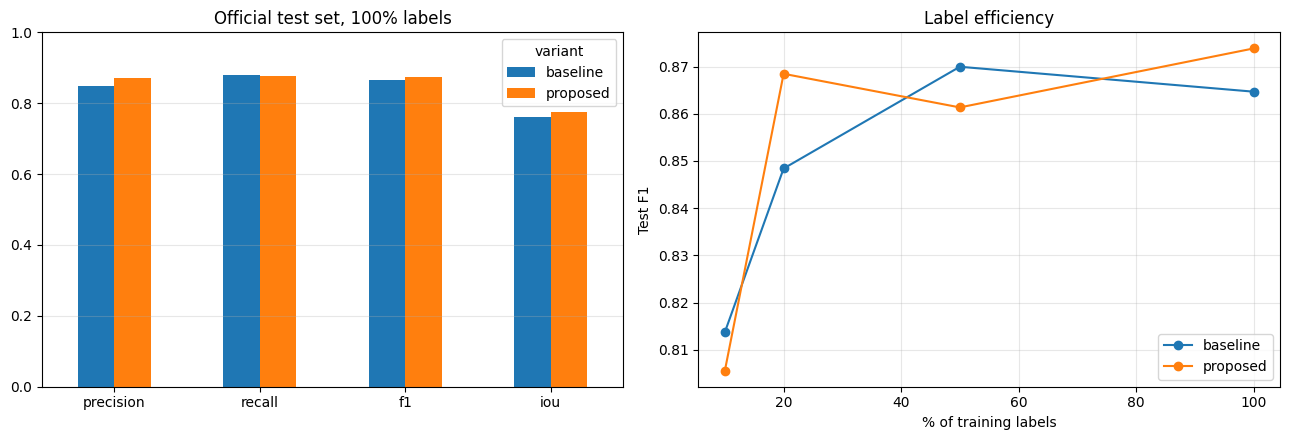

Saved: /content/drive/MyDrive/Building_Change_Detection/Edge_Guided_LoRA_Project/v2_improved/figures/results_overview.png


In [12]:
#cell 11
import pandas as pd
import matplotlib.pyplot as plt

rows = []
for p in sorted(V2["results"].glob("*_test.json")):
    r = json.loads(p.read_text())
    t = r["test_at_val_threshold"]
    rows.append({
        "run": r["name"], "variant": r["variant"], "labels": r["label_key"], "seed": r["seed"],
        "threshold": r["threshold"], "precision": t["precision"], "recall": t["recall"],
        "f1": t["f1"], "iou": t["iou"], "oa": t["oa"], "f1_at_0.5": r["test_at_0.5"]["f1"],
        "trainable_params": r["trainable_params"], "sec_per_image": r["latency_sec_per_image"],
    })
df = pd.DataFrame(rows)

if df.empty:
    print("No finished runs found yet - run section 9 first.")
else:
    pd.set_option("display.width", 200)
    print("ALL RUNS\n", df.round(4).to_string(index=False))
    df.to_csv(V2["results"] / "all_runs.csv", index=False)

    summary = df.groupby(["variant", "labels"])[["precision", "recall", "f1", "iou", "oa"]].agg(["mean", "std"]).round(4)
    print("\nSUMMARY (mean / std over seeds)\n", summary.to_string())
    summary.to_csv(V2["results"] / "summary_mean_std.csv")

    main = df[df["labels"] == "100%"].groupby("variant")[["precision", "recall", "f1", "iou"]].mean()
    if {"baseline", "proposed"}.issubset(main.index):
        d = main.loc["proposed"] - main.loc["baseline"]
        print("\nProposed - Baseline (100% labels, mean over seeds):")
        print(d.round(4).to_string())
        verdict = "IMPROVES on" if d["f1"] > 0 else "does NOT improve on"
        print(f"=> Proposed model {verdict} the baseline in F1 ({d['f1']:+.4f}). "
              f"{'Use 3 seeds (CFG[SEEDS]) before claiming significance.' if len(CFG['SEEDS']) < 3 else ''}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    mm = df[df["labels"] == "100%"].groupby("variant")[["precision", "recall", "f1", "iou"]].mean()
    mm.T.plot(kind="bar", ax=axes[0], rot=0)
    axes[0].set_title("Official test set, 100% labels"); axes[0].set_ylim(0, 1); axes[0].grid(axis="y", alpha=.3)

    df["frac"] = df["labels"].str.rstrip("%").astype(int)
    if df["frac"].nunique() > 1:
        for vname, g in df.groupby("variant"):
            gg = g.groupby("frac")["f1"].mean().sort_index()
            axes[1].plot(gg.index, gg.values, marker="o", label=vname)
        axes[1].set_xlabel("% of training labels"); axes[1].set_ylabel("Test F1")
        axes[1].set_title("Label efficiency"); axes[1].legend(); axes[1].grid(alpha=.3)
    else:
        axes[1].axis("off")
        axes[1].text(0.5, 0.5,ha="center", va="center")
    plt.tight_layout()
    plt.savefig(V2["figures"] / "results_overview.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", V2["figures"] / "results_overview.png")

## 12. Qualitative predictions on official test images

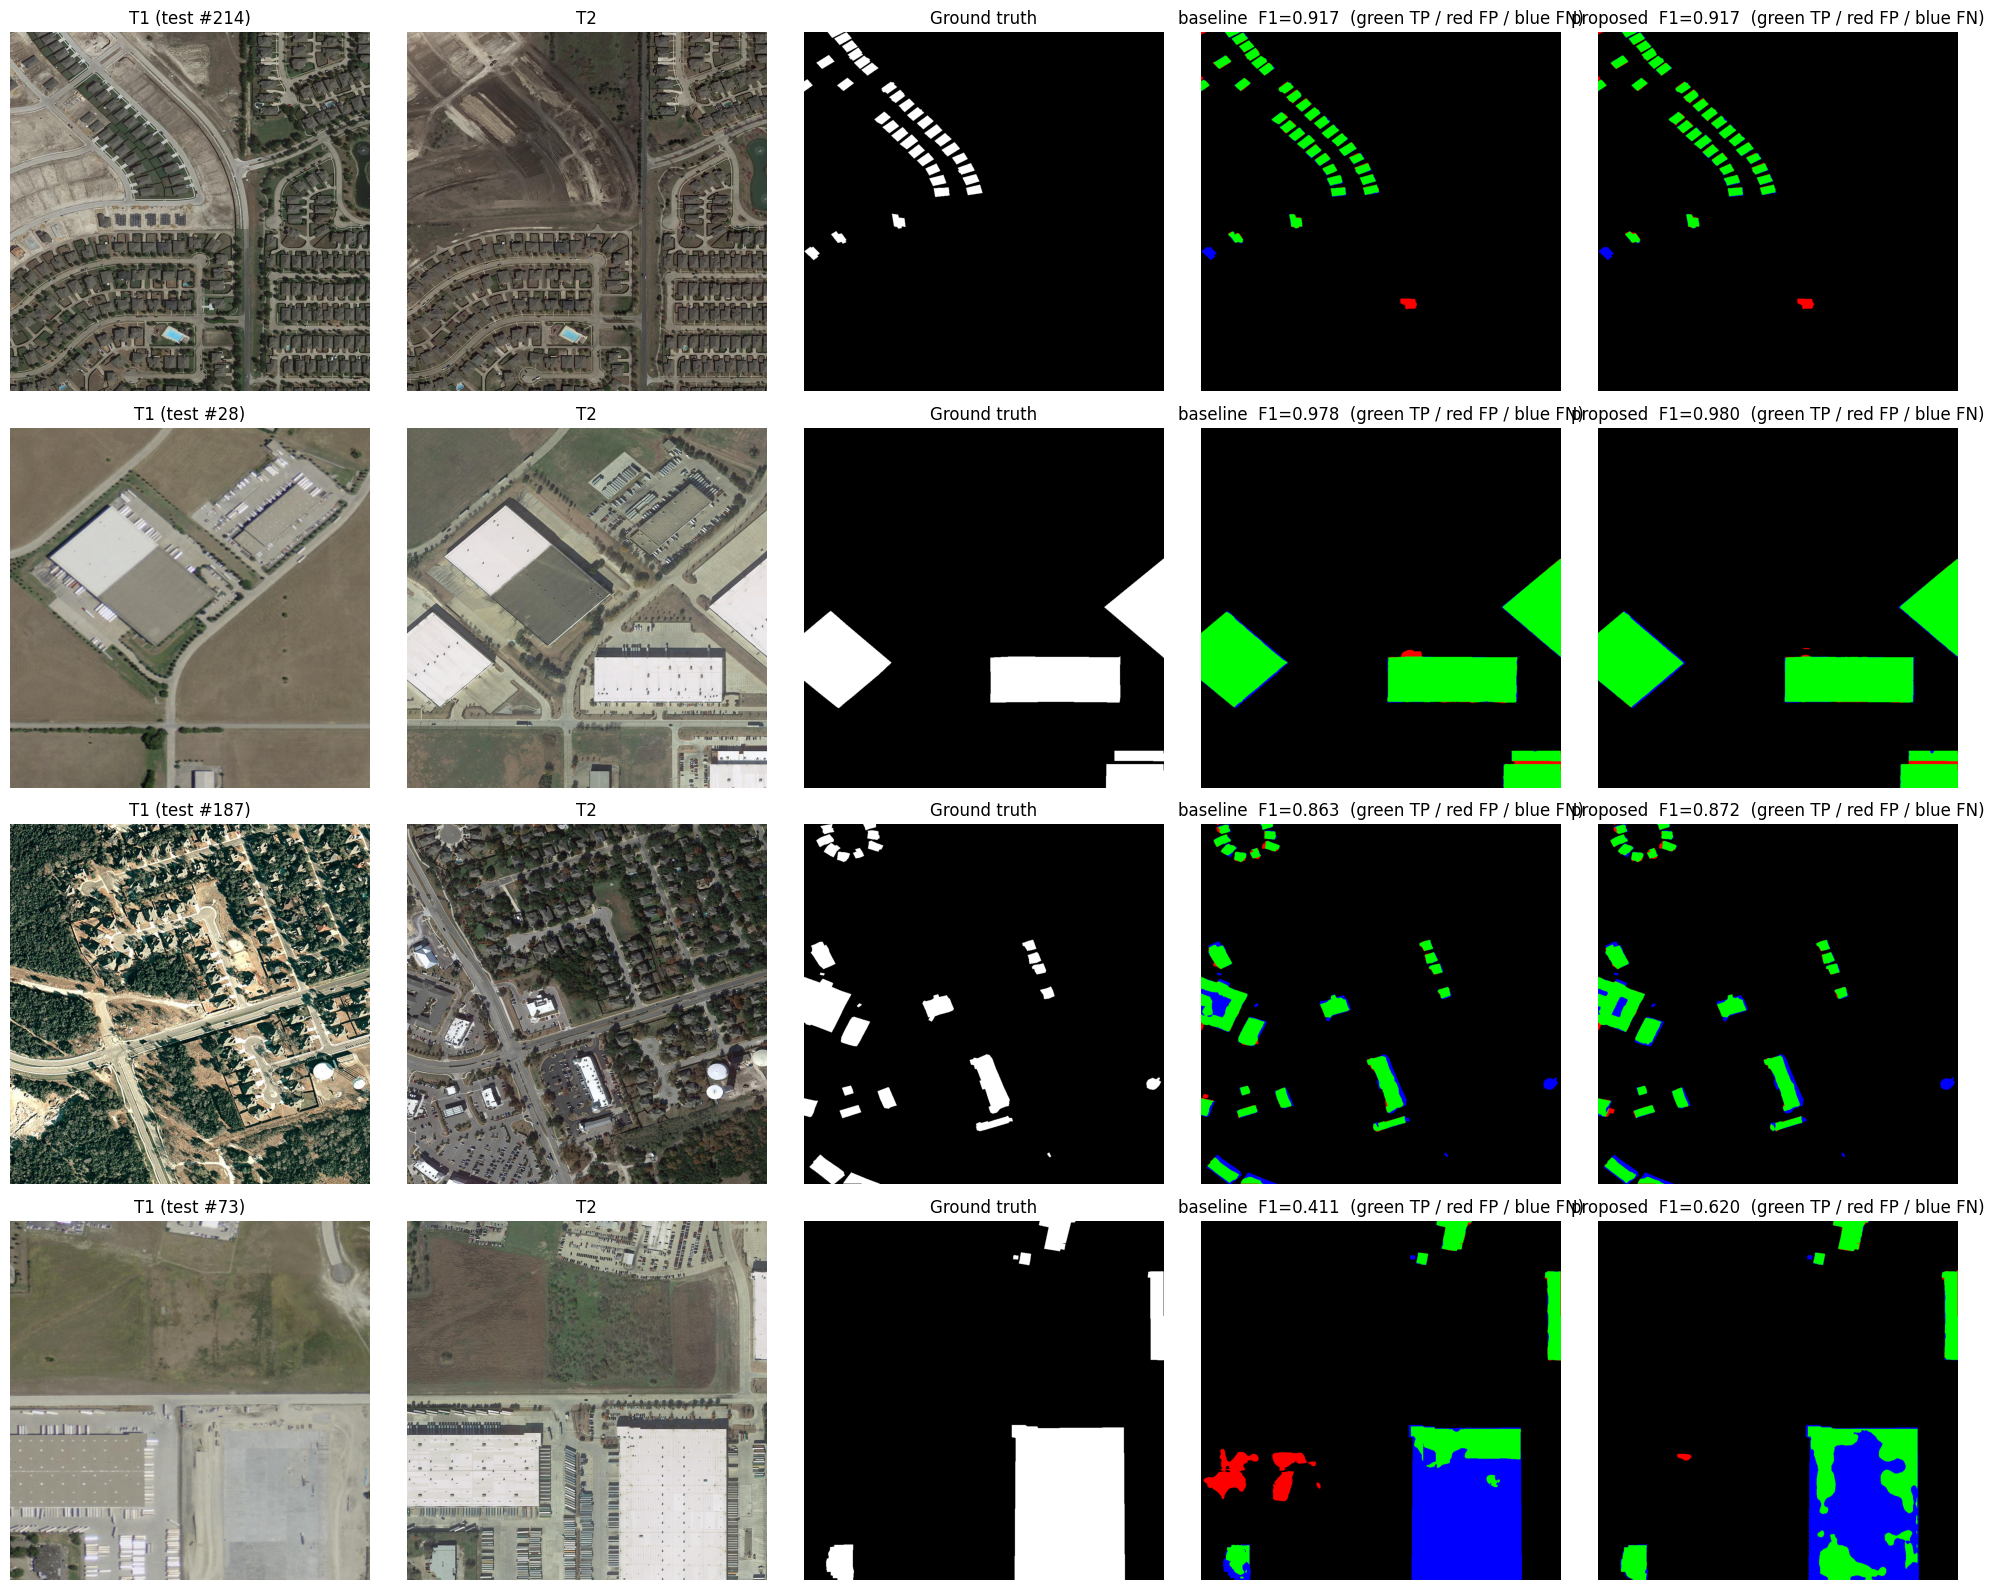

Saved: /content/drive/MyDrive/Building_Change_Detection/Edge_Guided_LoRA_Project/v2_improved/figures/qualitative_baseline_vs_proposed.png


In [13]:
#cell 12
import matplotlib.pyplot as plt

seed0 = CFG["SEEDS"][0]
res_b = V2["results"] / f"{exp_name('baseline', '100%', seed0)}_test.json"
res_p = V2["results"] / f"{exp_name('proposed', '100%', seed0)}_test.json"

if not (res_b.exists() and res_p.exists()):
    print("Both baseline and proposed results are required - run section 9 first.")
else:
    loaded = {}
    for vname, rp in [("baseline", res_b), ("proposed", res_p)]:
        r = json.loads(rp.read_text())
        m = build_model(VARIANTS[vname]["use_edge"])
        ck = torch.load(V2["checkpoints"] / r["name"] / "best.pt", map_location=device, weights_only=False)
        load_trainable(m, ck["model"])
        m.eval()
        loaded[vname] = (m, r["threshold"])

    arr = EVAL_ARR["test"]
    cand = [i for i in manifest["official_test_ids"] if 0.02 < float(arr["mask"][i].mean()) < 0.30]
    pick_rng = random.Random(0)
    pick_rng.shuffle(cand)
    chosen = cand[:4]

    def overlay_and_f1(prob, gt, thr):
        pred = (prob >= thr).cpu().numpy()
        g = gt.astype(bool)
        ov = np.zeros((*g.shape, 3), dtype=np.float32)
        ov[..., 1] = pred & g
        ov[..., 0] = pred & ~g
        ov[..., 2] = ~pred & g
        tp, fp, fn = (pred & g).sum(), (pred & ~g).sum(), (~pred & g).sum()
        return ov, (2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0)

    fig, axes = plt.subplots(len(chosen), 5, figsize=(20, 4 * len(chosen)))
    for r_i, idx in enumerate(chosen):
        gt = np.array(arr["mask"][idx])
        axes[r_i, 0].imshow(arr["t1"][idx]); axes[r_i, 0].set_title(f"T1 (test #{idx})")
        axes[r_i, 1].imshow(arr["t2"][idx]); axes[r_i, 1].set_title("T2")
        axes[r_i, 2].imshow(gt, cmap="gray", vmin=0, vmax=1); axes[r_i, 2].set_title("Ground truth")
        for c_i, vname in enumerate(["baseline", "proposed"]):
            m, thr = loaded[vname]
            prob = predict_full(m, arr["t1"][idx], arr["t2"][idx], tta=False)
            ov, f1 = overlay_and_f1(prob, gt, thr)
            axes[r_i, 3 + c_i].imshow(ov)
            axes[r_i, 3 + c_i].set_title(f"{vname}  F1={f1:.3f}  (green TP / red FP / blue FN)")
        for ax in axes[r_i]:
            ax.axis("off")
    plt.tight_layout()
    out_fig = V2["figures"] / "qualitative_baseline_vs_proposed.png"
    plt.savefig(out_fig, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", out_fig)
    for m, _ in loaded.values():
        del m
    del loaded
    gc.collect(); torch.cuda.empty_cache()